# **CRM Sales Pipeline Conversion Analysis**

## **Introduction**

### Executive Summary

Using 6,711 closed CRM deals, I tested two sales-team assumptions. Win rate did not differ across sectors ($p$ = 0.97, Cramér's V = 0.021), and won deals took about 10 days longer to close than lost deals, the opposite of the assumption that longer deals are less likely to be won. Deal duration is only weakly associated with winning (cross-validated ROC-AUC = 0.578) and is only known at close, so these results describe closed deals and can't be used to score open ones.

### Context

The sales operations team at a B2B computer hardware company requires data-driven insights to optimize pipeline resource allocation and lead prioritization. Currently, the sales team relies on unverified assumptions, specifically that (1) some customer sectors convert at higher rates, and (2) deals that take longer to close are less likely to be won. 

To address this need, I will analyze historical B2B sales pipeline data extracted from the CRM system. The analysis focuses on closed deals (won and lost outcomes) to evaluate relationships among final conversion success, customer business industry, and deal duration.

### Dataset scope

- **Records**: 6,711 (4,238 won, 2,473 lost)
- **Win rate**: 63.15%
- **Pipeline time period**: From the first engage date <u>2016-10-20</u> to the last close date <u>2017-12-31</u>.
- **Time span**: 437 days

### Research questions

1. Does win rate differ across customer sectors?
2. Do won and lost deals differ in deal duration?

## **Contents**

1. [Data Wrangling](#section-1): merge, cleaning, feature engineering
2. [Exploratory Data Analysis](#section-2): distributions, outcome comparisons
3. [Hypothesis Testing](#section-3): chi-square (sector) and Welch's t-test (deal duration)
4. [Supporting Analysis](#section-4): logistic regression and cross-validated ROC-AUC
5. [Key Findings & Recommendations](#section-5)

<a id="section-1"></a>
## **Section 1: Data Wrangling**

### Setup

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_curve
from sklearn.linear_model import LogisticRegression

### Data Ingestion

There are only two tables from the dataset that we will need for this analysis; sales_pipeline and accounts.

**Data dictionary (final):**

| Column | Description | Type | Source |
|---|---|---|---|
| `opportunity_id` | Unique deal identifier | string | Original |
| `account` | Company name | string | Original |
| `sector` | Company industry | string | Original |
| `deal_stage` | deal pipeline stage (Prospecting>Engaging>Won/Lost) | string | Original |
| `engage_date` | Date on which the deal entered the Engaging stage | datetime | Original |
| `close_date` | Date on which the deal was "Won" or "Lost" | datetime | Original |
| `deal_duration_days` | Time-to-close in days (`close_date` minus `engage_date`) | int | Derived |
| `is_won` | 1 if "Won", 0 if "Lost" based on `deal_stage` | int | Derived |

***Scope***: The other columns were left out because they are out of scope for the two research questions.

The data was downloaded as .csv files from Kaggle:  
CRM Sales Opportunities – Published by Mursaleen Ameer (https://www.kaggle.com/datasets/innocentmfa/crm-sales-opportunities/data)

We need to ingest both tables into Pandas Dataframes for data manipulation:

In [2]:
sales_df = pd.read_csv('data/raw/sales_pipeline.csv')

# validate that the number of columns and rows aligns with the data source
print(sales_df.shape)

# print first 5 rows
sales_df.head()

(8800, 8)


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0


In [3]:
accounts_df = pd.read_csv('data/raw/accounts.csv')

# validate that the number of columns and rows aligns with the data source
print(accounts_df.shape)

# print first 5 rows
accounts_df.head()

(85, 7)


,account,sector,year_established,revenue,employees,office_location,subsidiary_of
0,Acme Corporation,technolgy,1996,1100.04,2822,United States,NaN
1,Betasoloin,medical,1999,251.41,495,United States,NaN
2,Betatech,medical,1986,647.18,1185,Kenya,NaN
3,Bioholding,medical,2012,587.34,1356,Philipines,NaN
4,Bioplex,medical,1991,326.82,1016,United States,NaN


### Merge dataframes


Now we need to merge both dataframes into a single dataframe with the common account column variable.

In [4]:
# merge the two dataframes (tables) on the account column
merged_df = pd.merge(sales_df, accounts_df, on='account')

# validate that the number of columns and rows aligns with the merged tables
print(merged_df.shape)

# validate merge
merged_df.head()

(7375, 14)


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,sector,year_established,revenue,employees,office_location,subsidiary_of
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0,retail,2001,718.62,2448,United States,NaN
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0,medical,2002,3178.24,4540,United States,NaN
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0,retail,2001,718.62,2448,United States,NaN
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0,software,1998,2714.90,2641,United States,Acme Corporation
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0,services,1982,792.46,1299,United States,NaN


There's a reduction in rows, from 8800 down to 7375. Let's check why.

In [5]:
# check that the join doesn't multiply rows
check = sales_df.merge(accounts_df, on='account', how='left',
                       validate='m:1', indicator=True)

# show matching and unmatching rows
print(check['_merge'].value_counts())

# show deal stage of unmatched rows
print(check.loc[check['_merge'] == 'left_only', 'deal_stage'].value_counts())

# show rows with missing account names
print(f'Missing account names: {check.loc[check['_merge'] == 'left_only', 'account'].isna().sum()}')

_merge
both          7375
left_only     1425
right_only       0
Name: count, dtype: int64
deal_stage
Engaging       1088
Prospecting     337
Name: count, dtype: int64
Missing account names: 1425


1,425 deals (1,088 Engaging, 337 Prospecting) had no account name, so they did not match the accounts table. All are open deals, so no won or lost deal will be lost in the merge.

### Data Cleaning & Initial Filtering

In [6]:
# look at all the unique deal_stage values and counts
merged_df['deal_stage'].value_counts()

deal_stage
Won            4238
Lost           2473
Engaging        501
Prospecting     163
Name: count, dtype: int64

We only want to keep rows with 'Won' and 'Lost' deal_stage values.

In [7]:
# keep only rows with 'Won' and 'Lost' deal_stage values
merged_df = merged_df[merged_df['deal_stage'].isin(['Won','Lost'])].copy()

# validate changes
print(merged_df['deal_stage'].value_counts())

deal_stage
Won     4238
Lost    2473
Name: count, dtype: int64


After this, let's validate that each variable has the correct data type.

In [8]:
# check that all opportunity_id values are unique
assert merged_df['opportunity_id'].is_unique

# check that close_date is always later than engage_date
assert (merged_df['close_date'] >= merged_df['engage_date']).all()

# show if the number of categories is the same before and after trimming whitespaces and case sensitivity
print(merged_df['sector'].str.strip().str.lower().nunique(), merged_df['sector'].nunique())

10 10


In [9]:
# review variables data types
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6711 entries, 0 to 7211
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   opportunity_id    6711 non-null   object 
 1   sales_agent       6711 non-null   object 
 2   product           6711 non-null   object 
 3   account           6711 non-null   object 
 4   deal_stage        6711 non-null   object 
 5   engage_date       6711 non-null   object 
 6   close_date        6711 non-null   object 
 7   close_value       6711 non-null   float64
 8   sector            6711 non-null   object 
 9   year_established  6711 non-null   int64  
 10  revenue           6711 non-null   float64
 11  employees         6711 non-null   int64  
 12  office_location   6711 non-null   object 
 13  subsidiary_of     1160 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 786.4+ KB


Only engage_date and close_date need their data types to be changed. To allow us to make calculations, we will transform them from object data types to datetime.

In [10]:
# transforms date variables to datetime data type
merged_df['engage_date'] = pd.to_datetime(merged_df['engage_date'])
merged_df['close_date'] = pd.to_datetime(merged_df['close_date'])

# validate data type transformation
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6711 entries, 0 to 7211
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   opportunity_id    6711 non-null   object        
 1   sales_agent       6711 non-null   object        
 2   product           6711 non-null   object        
 3   account           6711 non-null   object        
 4   deal_stage        6711 non-null   object        
 5   engage_date       6711 non-null   datetime64[ns]
 6   close_date        6711 non-null   datetime64[ns]
 7   close_value       6711 non-null   float64       
 8   sector            6711 non-null   object        
 9   year_established  6711 non-null   int64         
 10  revenue           6711 non-null   float64       
 11  employees         6711 non-null   int64         
 12  office_location   6711 non-null   object        
 13  subsidiary_of     1160 non-null   object        
dtypes: datetime64[ns](2), float64

Both variables are now datetime data types.

Another important variable we will need it sector, so lets inspect the unique values and their counts:

In [11]:
# look at all the unique sector values and counts
merged_df['sector'].value_counts()

sector
retail                1267
technolgy             1058
medical                950
software               704
marketing              623
finance                613
telecommunications     456
entertainment          402
services               352
employment             286
Name: count, dtype: int64

All unique sectors have sufficient value counts for analysis. Other than "technology" being misspelled, there are no corrections needed.

So let's make the correction:

In [12]:
# replace "technolgy" with "technology"
merged_df['sector'] = merged_df['sector'].replace({'technolgy': 'technology'})

# validate changes
merged_df['sector'].value_counts()

sector
retail                1267
technology            1058
medical                950
software               704
marketing              623
finance                613
telecommunications     456
entertainment          402
services               352
employment             286
Name: count, dtype: int64

Let's inspect if there are any null variables

In [13]:
# inspect null values
print(merged_df.isnull().sum())

opportunity_id         0
sales_agent            0
product                0
account                0
deal_stage             0
engage_date            0
close_date             0
close_value            0
sector                 0
year_established       0
revenue                0
employees              0
office_location        0
subsidiary_of       5551
dtype: int64


Only subsidiary_of has null values, but this is normal and we won't be using it anyways, so no changes are needed.

### Feature Engineering

**deal_duration_days feature**:  
A helpful feature we will need for analysis is the deal duration (velocity) in days. We can create this by using the "close_date" minus (-) the "engage_date".

In [14]:
# create a new column with deal duration in days using the engage and close dates
merged_df['deal_duration_days'] = (merged_df['close_date'] - merged_df['engage_date']).dt.days

# validate new column
merged_df.head()

,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,sector,year_established,revenue,employees,office_location,subsidiary_of,deal_duration_days
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0,retail,2001,718.62,2448,United States,NaN,132
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0,medical,2002,3178.24,4540,United States,NaN,137
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0,retail,2001,718.62,2448,United States,NaN,133
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0,software,1998,2714.90,2641,United States,Acme Corporation,135
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0,services,1982,792.46,1299,United States,NaN,128


**is_won feature**:  
Earlier, we filtered deal_stage to only keep "Won" and "Lost" records. Now we will create a new column by converting these two valus to binary values for model fitting (1 = Won, 0 = Lost).

In [15]:
# create new column with binary deal_stage values (1 = Won, 0 = Lost)
merged_df['is_won'] = (merged_df['deal_stage'] == 'Won').astype(int)

# check unique is_won values
print(merged_df['is_won'].unique())

# validate new column
merged_df.head()

[1 0]


,opportunity_id,sales_agent,product,account,deal_stage,engage_date,close_date,close_value,sector,year_established,revenue,employees,office_location,subsidiary_of,deal_duration_days,is_won
0,1C1I7A6R,Moses Frase,GTX Plus Basic,Cancity,Won,2016-10-20,2017-03-01,1054.0,retail,2001,718.62,2448,United States,NaN,132,1
1,Z063OYW0,Darcel Schlecht,GTXPro,Isdom,Won,2016-10-25,2017-03-11,4514.0,medical,2002,3178.24,4540,United States,NaN,137,1
2,EC4QE1BX,Darcel Schlecht,MG Special,Cancity,Won,2016-10-25,2017-03-07,50.0,retail,2001,718.62,2448,United States,NaN,133,1
3,MV1LWRNH,Moses Frase,GTX Basic,Codehow,Won,2016-10-25,2017-03-09,588.0,software,1998,2714.90,2641,United States,Acme Corporation,135,1
4,PE84CX4O,Zane Levy,GTX Basic,Hatfan,Won,2016-10-25,2017-03-02,517.0,services,1982,792.46,1299,United States,NaN,128,1


In [16]:
# validate data types
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6711 entries, 0 to 7211
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   opportunity_id      6711 non-null   object        
 1   sales_agent         6711 non-null   object        
 2   product             6711 non-null   object        
 3   account             6711 non-null   object        
 4   deal_stage          6711 non-null   object        
 5   engage_date         6711 non-null   datetime64[ns]
 6   close_date          6711 non-null   datetime64[ns]
 7   close_value         6711 non-null   float64       
 8   sector              6711 non-null   object        
 9   year_established    6711 non-null   int64         
 10  revenue             6711 non-null   float64       
 11  employees           6711 non-null   int64         
 12  office_location     6711 non-null   object        
 13  subsidiary_of       1160 non-null   object        
 1

In [17]:
# get the dataset's date range and time span
print(f'Pipeline time period: from {merged_df['engage_date'].dt.date.min()} to {merged_df['close_date'].dt.date.max()}')

time_span = merged_df['close_date'].max() - merged_df['engage_date'].min()

print(f'Time span: {time_span.days} days ({round(time_span.days / 30.44, 1)} months)')

Pipeline time period: from 2016-10-20 to 2017-12-31
Time span: 437 days (14.4 months)


### Variable selection & Export

In [18]:
# list columns we will keep
keep_columns = [
    'opportunity_id',
    'account',
    'sector',
    'deal_stage',
    'is_won',
    'deal_duration_days'
]

# make copy of the dataframe with only the column list
df_clean = merged_df[keep_columns].copy()

# validate new dataframe columns
df_clean.head()

,opportunity_id,account,sector,deal_stage,is_won,deal_duration_days
0,1C1I7A6R,Cancity,retail,Won,1,132
1,Z063OYW0,Isdom,medical,Won,1,137
2,EC4QE1BX,Cancity,retail,Won,1,133
3,MV1LWRNH,Codehow,software,Won,1,135
4,PE84CX4O,Hatfan,services,Won,1,128


Before exporting the clean data, let's make sure there are no duplicate records.

In [19]:
# check duplicates
duplicates_count = df_clean.duplicated().sum()
print(duplicates_count)

0


**Export clean dataset**

In [20]:
# create 'data/clean' folder path
Path('data/clean').mkdir(parents=True, exist_ok=True)

# export clean data for reuse
df_clean.to_csv('data/clean/crm_sales_cleaned.csv', index=False, encoding="utf-8")

<a id="section-2"></a>
## **Section 2: Exploratory Data Analysis (EDA) & Summary Statistics**

### Univariate analysis

#### - Sector

**Frequency counts and percentage**

In [21]:
# frequency counts and percentage table for each sector
sector_summary = pd.DataFrame({
    'Count': df_clean['sector'].value_counts(),
    'Percentage (%)': (df_clean['sector'].value_counts(normalize=True) * 100).round(2)
})
print(sector_summary)

                    Count  Percentage (%)
sector                                   
retail               1267           18.88
technology           1058           15.77
medical               950           14.16
software              704           10.49
marketing             623            9.28
finance               613            9.13
telecommunications    456            6.79
entertainment         402            5.99
services              352            5.25
employment            286            4.26


#### - Deal stage

**Frequency counts and percentage**

In [22]:
# frequency counts and percentage table for each deal stage
stage_summary = pd.DataFrame({
    'Count': df_clean['deal_stage'].value_counts(),
    'Percentage (%)': (df_clean['deal_stage'].value_counts(normalize=True) * 100).round(2)
})
print(stage_summary)

            Count  Percentage (%)
deal_stage                       
Won          4238           63.15
Lost         2473           36.85


This indicates that there is a **63.15% win rate** in general over all sectors.

#### - Deal duration days

**Summary metrics**

In [23]:
# generate descriptive statistics
df_clean['deal_duration_days'].describe().round(2)

count    6711.00
mean       47.99
std        41.06
min         1.00
25%         8.00
50%        45.00
75%        85.00
max       138.00
Name: deal_duration_days, dtype: float64

A quick look into deal duration summary statistics shows that the average deal duration is about 48 days and the median is 45.  
A deal can extend up to 138 days.

**Histogram: Distribution shape**

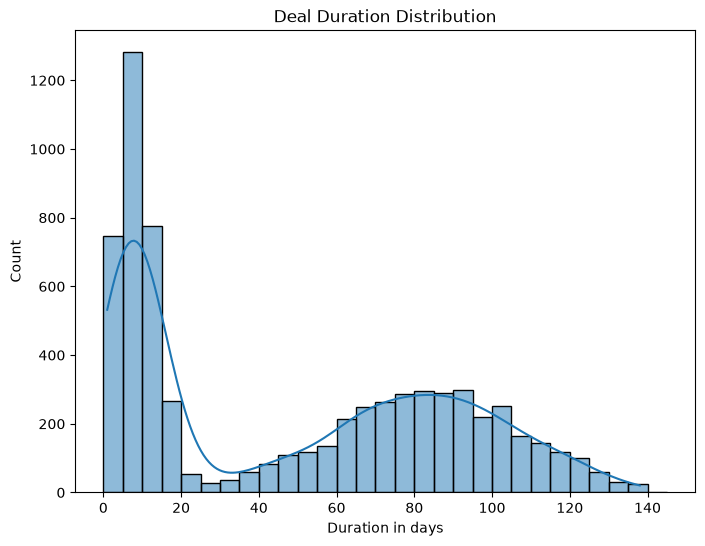

In [24]:
# make 5 day bins
bins = np.arange(0, df_clean['deal_duration_days'].max() + 10, 5)

plt.figure(figsize=(8, 6))

# create deal duration histogram
sns.histplot(data=df_clean, x='deal_duration_days', bins=bins, kde=True)

plt.xlabel('Duration in days')
plt.title('Deal Duration Distribution')
plt.show()

From this positively skewed bimodal distribution, we can see that there is an important concentration of deals that last only 5-15 days. This number rapidly drops and rises again as we start seeing a large volume of deals lasting ~60-110 days before it drops a second time up to 140 days. Because of this shape, the overall mean (47.99) and median (45) sit between the clusters/modals (the valley between them) and don’t describe a typical deal.

**Box plot: Dispersion**

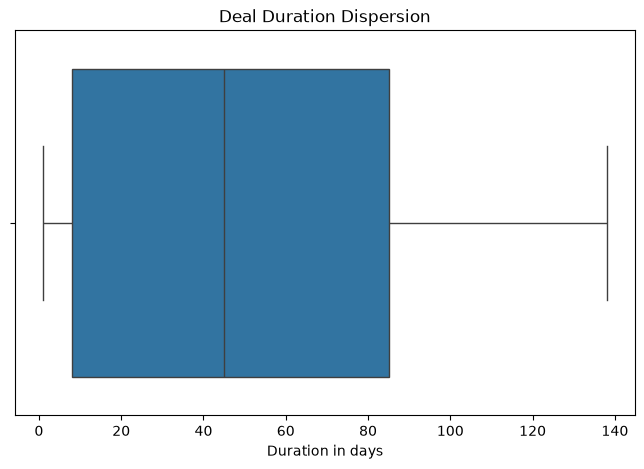

In [25]:
plt.figure(figsize=(8, 5))

# create deal duration box plot
sns.boxplot(data=df_clean, x='deal_duration_days')

plt.xlabel('Duration in days')
plt.title('Deal Duration Dispersion')
plt.show()

### Bivariate analysis

#### - Deal stage vs. deal duration

**Summary metrics**

In [26]:
# group by deal outcome and calculate summary metrics
duration_by_outcome = df_clean.groupby('deal_stage')['deal_duration_days'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Std_Dev='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
).round(2)

duration_by_outcome

,Count,Mean,Median,Std_Dev,IQR
deal_stage,,,,,
Lost,2473,41.48,14.0,40.04,72.0
Won,4238,51.78,57.0,41.17,79.0


**Won vs Lost mean and median difference**

In [27]:
# calculate mean deal_stage difference (mean 'Won' - mean 'Lost')
mean_outcome_diff = (df_clean[df_clean['deal_stage'].isin(['Won'])]['deal_duration_days'].mean() - df_clean[df_clean['deal_stage'].isin(['Lost'])]['deal_duration_days'].mean()).round(2)

# calculate median deal_stage difference (median 'Won' - median 'Lost')
median_outcome_diff = (df_clean[df_clean['deal_stage'].isin(['Won'])]['deal_duration_days'].median() - df_clean[df_clean['deal_stage'].isin(['Lost'])]['deal_duration_days'].median()).round(2)

print(f'Mean difference: {mean_outcome_diff}')
print(f'Median difference: {median_outcome_diff}')

Mean difference: 10.3
Median difference: 43.0


The mean gap between won and lost deals is 10.3 days, but the median gap is 43 days. This difference suggests the means understate how much the typical won and lost deals differ, so a rank-based test is included alongside the t-test as a robustness check.

**Box plot: Dispersion (by outcome)**

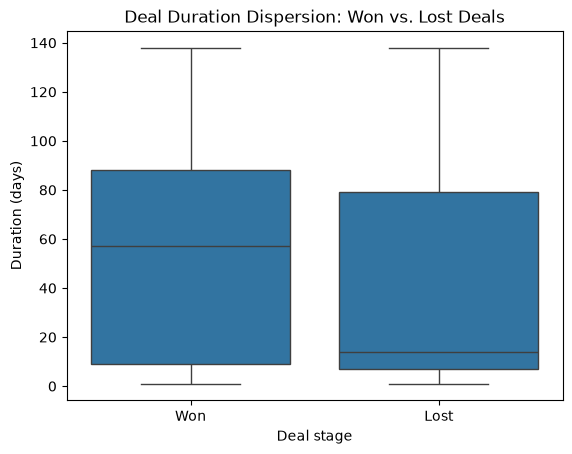

In [28]:
# create side-by-side box plots
sns.boxplot(data=df_clean, x='deal_stage', y='deal_duration_days')

plt.xlabel('Deal stage')
plt.ylabel('Duration (days)')
plt.title('Deal Duration Dispersion: Won vs. Lost Deals')
plt.show()

Evidently, the won deals have a higher duration interquartile distribution. Most notably once again is the median.

**Histogram: Distribution shape (won vs. lost)**

We previously saw a univariate deal duration histogram for all outcomes. Let's now see how it looks if we separate won vs. lost outcomes. To do this, we will use bins represented by percentages relative to the total of each outcome. This will allow us to compare both values' distributions on equal therms. 

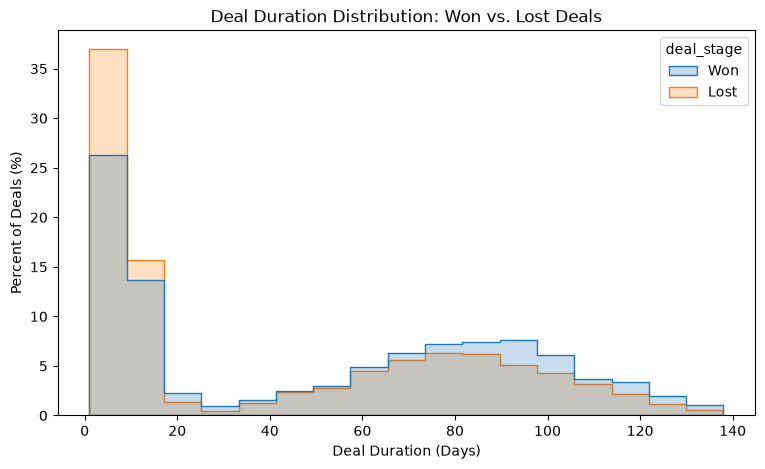

In [29]:
plt.figure(figsize=(9,5))

# create histogram deal_stage percentage distribution
sns.histplot(
    data=df_clean,
    x='deal_duration_days',
    hue="deal_stage",
    element='step',
    stat='percent',
    common_norm=False
)

plt.title('Deal Duration Distribution: Won vs. Lost Deals')

# create x and y labels
plt.xlabel('Deal Duration (Days)')
plt.ylabel('Percent of Deals (%)')

# create reports/figures folder path
Path('reports/figures').mkdir(parents=True, exist_ok=True)

# save plot to reports/figures (for documentation and reports)
plt.savefig('reports/figures/deal_duration_won_vs_lost.png', dpi=150, bbox_inches='tight')

plt.show()

While the distribution for both outcomes (won and lost) follow a similar pattern, when we look closely, lost deals are concentrated in the first mode (short durations), while won deals are spread more evenly between the two modes. This is consistent with the lower median for lost deals (14 vs. 57 days).

**Exploratory check for quick closed deals (Won Vs. Lost)**

In [30]:
# make a series of booleans based on if a deal closed within 15 days or not
# 15 days marks the end of the first mode in the histogram
quick = (df_clean['deal_duration_days'] <= 15).rename('quick_close')

# show the win rate within each quick_close group (rows sum to 100%)
print(f'Win rate on quick_close: \n {pd.crosstab(quick, df_clean['deal_stage'], normalize='index').round(3) * 100} \n')

# show a cross table with the share of each outcome that closed quickly (columns sum to 100%)
print(f'Share per outcome: \n {pd.crosstab(quick, df_clean['deal_stage'], normalize='columns').round(3) * 100} \n')

# show counts, so percentages come with sample sizes
print(f'Counts: \n {pd.crosstab(quick, df_clean['deal_stage'], margins=True)}')

Win rate on quick_close: 
 deal_stage   Lost   Won
quick_close            
False        31.5  68.5
True         43.9  56.1 

Share per outcome: 
 deal_stage   Lost   Won
quick_close            
False        48.9  61.9
True         51.1  38.1 

Counts: 
 deal_stage   Lost   Won   All
quick_close                  
False        1209  2625  3834
True         1264  1613  2877
All          2473  4238  6711


About 51% of lost deals closed within 15 days (the first mode), compared with 38% of won deals. Quick closes are therefore over-represented among lost deals, although most quick closes (56%) were still won. Lost deals represent 36.9% of all deals but 43.9% of quick closes.

This is exploratory: the 15-day cutoff was chosen from the histogram, and the data can’t explain why quick deals are lost more often.

#### - Deal stage vs. Sector

**Contingency table:** Win rate by sector

In [31]:
# create a base contingency table with total row/column margins
sector_crosstab = pd.crosstab(
    df_clean['sector'], 
    df_clean['deal_stage'], 
    margins=True, 
    margins_name='Total'
)

# calculate win rate percentage
sector_crosstab['Win Rate (%)'] = ((sector_crosstab['Won'] / sector_crosstab['Total']) * 100).round(1)

print(f'Min win rate (%): {sector_crosstab['Win Rate (%)'].min()}')
print(f'Max win rate (%): {sector_crosstab['Win Rate (%)'].max()}')

# display the formatted table
sector_crosstab

Min win rate (%): 61.2
Max win rate (%): 64.8


deal_stage,Lost,Won,Total,Win Rate (%)
sector,,,,
employment,107,179,286,62.6
entertainment,142,260,402,64.7
finance,238,375,613,61.2
marketing,219,404,623,64.8
medical,358,592,950,62.3
retail,468,799,1267,63.1
services,129,223,352,63.4
software,254,450,704,63.9
technology,387,671,1058,63.4


We can clearly see that the win rate across all the industry sectors is almost identical, ranging from 61.2% to 64.8%. Therefore, sector doesn't seem to have a meaningful impact on deal outcomes. This relationship will be more rigorously tested for statistical significance later on. 

**Bar chart**

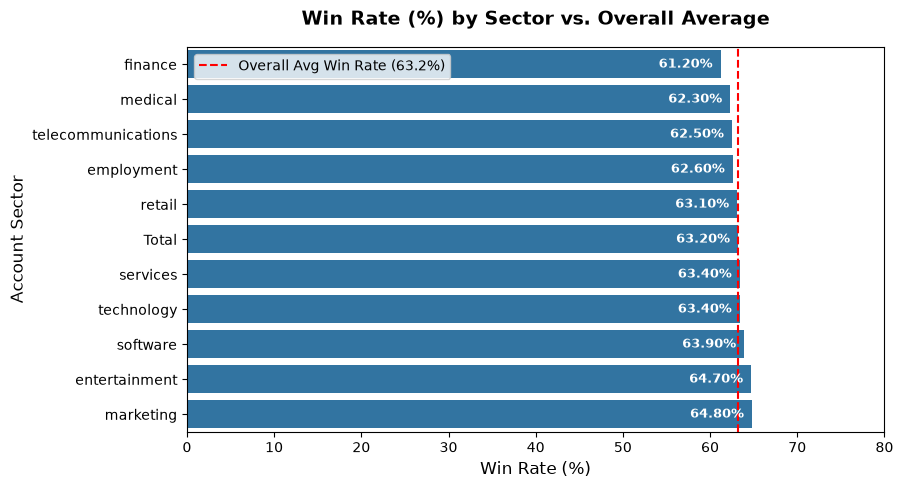

In [32]:
# sort plot data directly from the crosstab
plot_data = (sector_crosstab.sort_values("Win Rate (%)", ascending=True))

plt.figure(figsize=(9, 5))

# bar plot of win rates
ax = sns.barplot(data=plot_data, x="Win Rate (%)", y="sector")

# add overall baseline win rate line (63.15%)
overall_win_rate = sector_crosstab.loc["Total", "Win Rate (%)"]
plt.axvline(
    x=overall_win_rate,
    color='red',
    linestyle="--",
    label=f"Overall Avg Win Rate ({overall_win_rate}%)",
)

# annotate percentages on the bars
for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"{width:.2f}%",
        (width - 4, p.get_y() + p.get_height() / 2.0),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=9,
    )

plt.title(
    "Win Rate (%) by Sector vs. Overall Average",
    fontsize=14,
    fontweight="bold",
    pad=16,
)

plt.xlabel("Win Rate (%)", fontsize=12)
plt.ylabel("Account Sector", fontsize=12)

# standardize scale
plt.xlim(0, 80)
plt.legend(loc="upper left", frameon=True)
plt.show()

<a id="section-3"></a>
## **Section 3: Inferential Statistics & Hypothesis Testing**
Chi-Square Test of Independence & Independent Samples T-Test

#### Test 1: Sector (Chi-Square)

$H_0:$ Win rate is the same across all sectors (deal outcome is independent of sector).

$H_1:$ Win rate differs for at least one sector.

Significance level ($a$): 0.05

In [33]:
# create contingency table
contingency_table = pd.crosstab(df_clean['sector'], df_clean['deal_stage'])

# run Chi-Square Test
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(contingency_table)

# check for minimum expected counts (>= 5)
print('Smallest expected count:', expected.min().round(1))
print('All expected counts >= 5:', (expected >= 5).all())

# effect size: Cramér's V (with a 2-column table, min(rows, cols) - 1 = 1)
n = contingency_table.values.sum()
cramers_v = np.sqrt(chi2_stat / n)

# print results
print(f"Chi2 Statistic: {chi2_stat:.4f}")
print(f"Degrees of Freedom: {dof}")
print(f"p-value: {p_val_chi2:.4f}")
print(f"Cramér's V: {cramers_v:.3f}")

Smallest expected count: 105.4
All expected counts >= 5: True
Chi2 Statistic: 2.8313
Degrees of Freedom: 9
p-value: 0.9706
Cramér's V: 0.021


Once again, win rates ranged 61.2% to 64.8% across all sectors. The chi-square test found no evidence that win rate differs across them (χ² = 2.83, dof = 9, p = 0.97), so we fail to reject $H_0$. The statistic is well below the value of about 9 expected on average under $H_0$ with 9 degrees of freedom, and the association is negligible (Cramér’s V = 0.021). If sector had no effect on outcome, differences in win rate this large or larger would be expected about 97% of the time, so the observed variation across sectors is consistent with chance. 

All expected counts were at least 5, with a minimum expected count of 105.4, so the test’s assumptions are met.

#### Test 2: Deal duration (T-test)

$H_0: \mu_{won} = \mu_{lost}$ — The mean deal duration is the same for won and lost deals.

$H_1: \mu_{won} \neq \mu_{lost}$ — The mean deal duration differs between won and lost deals.

Significance level (a): 0.05

In [34]:
won = df_clean[df_clean['deal_stage'] == 'Won']['deal_duration_days']
lost = df_clean[df_clean['deal_stage'] == 'Lost']['deal_duration_days']

# run Welch's t-test (does not assume equal variances)
t_res = stats.ttest_ind(won, lost, equal_var=False)
ci = t_res.confidence_interval()   # CI for mean(won) - mean(lost)

print(f"Mean difference (won - lost): {won.mean() - lost.mean():.2f} days")
print(f"95% CI: [{ci.low:.2f}, {ci.high:.2f}]")
print(f"t = {t_res.statistic:.4f}, p = {t_res.pvalue:.4f} \n")

# check robustness with Mann-Whitney U (rank-based)
u_res = stats.mannwhitneyu(won, lost, alternative='two-sided')

# take the probability that a random won deal took longer than a random lost deal
prob_superiority = u_res.statistic / (len(won) * len(lost))
print(f"Mann-Whitney p = {u_res.pvalue:.4f}")
print(f"P(won deal takes longer than lost deal) = {prob_superiority:.3f}")

Mean difference (won - lost): 10.30 days
95% CI: [8.30, 12.31]
t = 10.0627, p = 0.0000 

Mann-Whitney p = 0.0000
P(won deal takes longer than lost deal) = 0.578


Won deals took longer to close than lost deals (mean difference 10.30 days, 95% CI [8.30, 12.31]; Welch's $t$ = 10.06, $p$ < 0.001), so we reject $H_0$. The Mann-Whitney U test agreed ($p$ < 0.001).

- **95% confidence interval**: The true mean difference is plausibly between about 8 and 12 days. The interval excludes 0, which is consistent with rejecting $H_0$.

- **$t$-statistic**: At 10.06, the observed gap is about 10 standard errors away from 0, far beyond the roughly ±2 expected from sampling noise alone.

- **$p$-value**: If mean duration were truly the same for won and lost deals, a gap this large or larger would be very unlikely ($p$ < 0.001). This is a statistically significant difference in duration.

- **Mann-Whitney U (robustness check)**: Because the duration distribution is bimodal, I confirmed the result with a rank-based test, which tests whether one group tends to have larger values than the other. It agrees with the t-test ($p$ < 0.001). If you pick one won deal and one lost deal at random, the won deal took longer 57.8% of the time (0.5 would mean no difference), so the effect is modest in size even though it is statistically clear.

The median gap (43 days) is much larger than the mean gap, but both point in the same direction. This contradicts the assumption that longer deals are less likely to be won.

<a id="section-4"></a>
## **Section 4: Supporting Analysis** (Logistic Regression)

**How strongly is deal duration associated with winning?**

The hypothesis tests above show that won and lost deals differ in deal duration, but not how much duration matters for a deal's outcome. A logistic regression adds two things: 

1. An effect size on the odds scale (how much the odds of winning change per additional day), 
2. And a measure of how well duration alone separates won from lost deals (ROC-AUC, estimated with cross-validation grouped by account). 

This is a supporting analysis of research question 2, not a prediction model, since deal duration is only known once a deal has closed.

### Fit the Model

The following binary **logistic regression** evaluates the relationship between deal duration and deal outcome.

In [35]:
# fit logistic regression using Statsmodels
logistic_model = smf.logit('is_won ~ deal_duration_days', data=df_clean).fit()

# display full regression summary table
print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.650742
         Iterations 4
                           Logit Regression Results                           
Dep. Variable:                 is_won   No. Observations:                 6711
Model:                          Logit   Df Residuals:                     6709
Method:                           MLE   Df Model:                            1
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                 0.01126
Time:                        21:20:20   Log-Likelihood:                -4367.1
converged:                       True   LL-Null:                       -4416.9
Covariance Type:            nonrobust   LLR p-value:                 1.995e-23
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.2486      0.038      6.508      0.000       0.174       0.323
deal_

After running the model, we can observe that **it is statistically significant** (LLR $p$ < 0.001), consistent with the t-test.

McFadden's pseudo-R² is 0.011, meaning the model's log-likelihood is only about **1.1% better than that of a model with no predictors**, so the improvement in fit is very small.

### Odds Ratio

In [36]:
# extract parameters and compute Odds Ratios with 95% Confidence Intervals
odds_ratios = np.exp(logistic_model.params)
conf_int = np.exp(logistic_model.conf_int())

# combine into a clean DataFrame
results_df = pd.DataFrame({
    'Coefficient (Log-Odds)': logistic_model.params,
    'Odds Ratio': odds_ratios,
    '2.5% CI': conf_int[0],
    '97.5% CI': conf_int[1]
})

print(f'For 10 days: {((np.exp(10 * logistic_model.params['deal_duration_days']) - 1) * 100).round(1)}%')
print(f'For 30 days: {((np.exp(30 * logistic_model.params['deal_duration_days']) - 1) * 100).round(1)}%')

results_df.round(4)

For 10 days: 6.4%
For 30 days: 20.6%


,Coefficient (Log-Odds),Odds Ratio,2.5% CI,97.5% CI
Intercept,0.2486,1.2822,1.1897,1.3819
deal_duration_days,0.0062,1.0063,1.0050,1.0075


The 1.0063 odds ratio indicates that each additional day is associated with a 0.63% increase in the odds of winning:

$$\text{Percentage Change} = (\text{Odds Ratio} - 1) \times 100$$
$$(1.0063 - 1) \times 100 = \mathbf{+0.63\%}$$

The 95% confidence interval (1.0050 to 1.0075) suggests the true increase is plausibly between 0.50% and 0.75% per day. Because the effect compounds, 10 extra days corresponds to about 6.4% higher odds of winning, and 30 extra days to about 21%.

Deal duration is therefore associated with winning, but the association is modest: as the ROC-AUC below shows, duration alone separates won from lost deals only weakly.

### ROC Curve

Grouped CV ROC-AUC: 0.578 (± 0.013 across folds)


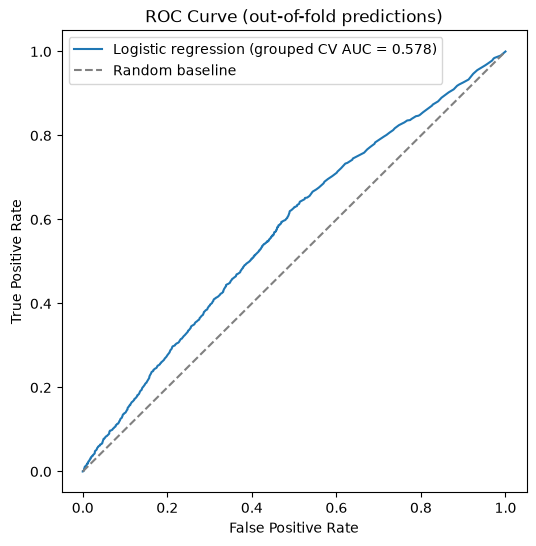

In [37]:
# get the predictor, target, and account groups
x = df_clean[['deal_duration_days']]
y = df_clean['is_won']
groups = df_clean['account']

# GroupKFold keeps all of an account's deals in the same fold,
# so each test fold contains accounts the model has not seen
cv = GroupKFold(n_splits=5)

# run ROC-AUC per fold, grouped by account
fold_auc = cross_val_score(LogisticRegression(), x, y,
                           scoring='roc_auc', cv=cv, groups=groups)
print(f"Grouped CV ROC-AUC: {fold_auc.mean():.3f} (± {fold_auc.std():.3f} across folds)")

# get Out-of-fold probabilities for the ROC curve
oof_probs = cross_val_predict(LogisticRegression(), x, y, cv=cv,
                              groups=groups, method='predict_proba')[:, 1]
fpr, tpr, _ = roc_curve(y, oof_probs)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic regression (grouped CV AUC = {fold_auc.mean():.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (out-of-fold predictions)')
plt.legend()
plt.show()

The grouped cross-validated ROC-AUC is 0.578 (± 0.013 across folds). This means that if you pick one won deal and one lost deal at random, the model gives the won deal the higher score 57.8% of the time, which is the same number as the Mann-Whitney result above. The ROC curve sits close to the random baseline, so deal duration alone has limited power to separate won from lost deals, even though the coefficient is positive and statistically significant.

In [38]:
# check the cutoff, whether every predicted probability is above 0.50
print(f"Lowest out-of-fold predicted win probability: {oof_probs.min():.3f}")
print(f"Share of deals predicted 'won' at 0.50 cutoff: {(oof_probs >= 0.5).mean():.1%}")
print(f"Baseline win rate: {y.mean():.2%}")

Lowest out-of-fold predicted win probability: 0.554
Share of deals predicted 'won' at 0.50 cutoff: 100.0%
Baseline win rate: 63.15%


At the default 0.50 cutoff, the model classifies every deal as won: the lowest out-of-fold predicted win probability was 0.554, and 100% of deals were predicted as won. 

Its accuracy therefore equals the baseline win rate (63.15%), so accuracy and a confusion matrix are not informative here, and ROC-AUC, which doesn't depend on a cutoff, is used instead.

**Conclusion**: The model is statistically significant (LLR *p* < 0.001), consistent with the t-test. But deal duration separates won from lost deals only weakly: McFadden's pseudo-R² is 0.011, a very small improvement in fit over a model with no predictors, and the grouped cross-validated ROC-AUC is about 0.58, close to the 0.50 expected from chance. Deal duration is associated with winning, but it is not useful on its own for telling won and lost deals apart.

<a id="section-5"></a>
## **Section 5: Key Findings & Recommendations**

### Answering the research questions

**1. Does win rate differ across customer sectors?**

There is no evidence of a difference. Win rates ranged only from 61.2% to 64.8% across sectors, and a chi-square test found no association between sector and outcome ($\chi^2 = 2.83$, dof = 9, $p$ = 0.97, Cramér's V = 0.021).

**2. Do won and lost deals differ in deal duration?**

Yes, and in the opposite direction from the sales team's assumption. Won deals took longer to close (mean difference 10.30 days, 95% CI [8.30, 12.31]; Welch's $t$ = 10.06, $p$ < 0.001), and a Mann-Whitney U test agreed. The effect is modest: a randomly chosen won deal took longer than a randomly chosen lost deal 57.8% of the time.

### Key findings

- **No detectable sector effect on win rate.** Differences in win rate across sectors are consistent with chance, so this data gives no support for the assumption that some sectors convert better.

- **Won deals take longer to close.** Won deals averaged 51.78 days vs. 41.48 days for lost deals. Because deal duration is bimodal, the median gap (43 days) is much larger than the mean gap. The data do not support the assumption that longer deals are less likely to be won.

- **Quick closes are over-represented among lost deals.** About 51% of lost deals closed within 15 days, compared with 38% of won deals, although most quick closes (56%) were still won. This is an exploratory finding, and the data can't explain why.

- **Deal duration alone separates won from lost deals only weakly.** Each additional day is associated with 0.63% higher odds of winning (odds ratio 1.0063), but the grouped cross-validated ROC-AUC is 0.578 and McFadden's pseudo-R² is 0.011, so the association is modest.

### Recommendations

1. **Don't prioritize leads by sector alone.** Win rates were nearly identical across sectors in this data, so sector isn't a useful basis for deciding which deals to favor.

2. **Don't treat a long deal duration as a warning sign by itself.** Won deals took longer to close on average. An unusually quick close isn't automatically a good sign either, since quick closes were over-represented among lost deals.

3. **Track open-deal age.** This analysis covers only closed deals, so it can't show whether open deals are stagnating. Recording how long each open deal has been in the pipeline (ideally as periodic snapshots) would make that analysis possible.

4. **Move toward multi-variable lead scoring.** Neither sector nor deal duration is enough on its own. A lead-score model should draw on information available while a deal is still open, such as deal value, product, account characteristics, and open-deal age, rather than deal duration at close.

### Limitations

- Only closed deals (won and lost) are analyzed, so the results don't address open-deal stagnation.
- Deal duration is only observed at close and is partly shaped by the outcome (for example, quick losses), so the results are descriptive and don't show that longer deals cause wins.
- Accounts repeat across deals, so observations aren't fully independent, and p-values may be somewhat optimistic.
- Results come from one dataset covering about 14 months, so they may not generalize to other periods or companies.

### Next steps

- Build a lead-score model using features known while deals are still open.
- Analyze open-deal age once snapshot data is available.
- Investigate what distinguishes quick-closing deals from slower ones (for example product, price, region, or sales team).